In [1]:
!pip install -q xgboost lightgbm catboost imbalanced-learn statsmodels openpyxl

In [3]:
import io, json, os, random, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from scipy import stats
from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              StackingClassifier, StackingRegressor)
from sklearn.feature_selection import RFE, RFECV, mutual_info_classif
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV
from sklearn.metrics import (accuracy_score, brier_score_loss, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, KFold, StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.contingency_tables import mcnemar

warnings.filterwarnings("ignore")

# ---------------- settings ----------------
FAST = False          # True = fewer trees, quick check only
RUN_NESTED = True     # False = skip nested-CV tuning
SEED = 42
random.seed(SEED); np.random.seed(SEED)
N_TREES = 100 if FAST else 300
LASSO_C = 0.1
RF_PARAMS = dict(n_estimators=N_TREES, max_depth=8)
XGB_PARAMS = dict(n_estimators=N_TREES, max_depth=5, learning_rate=0.05)
LGBM_PARAMS = dict(n_estimators=N_TREES, learning_rate=0.05)
CATBOOST_PARAMS = dict(iterations=N_TREES, depth=6, learning_rate=0.05)

CV_CLS, CV_REG, CV_RFE = 10, 5, 5          # folds
NESTED_OUTER, NESTED_INNER = 5, 3
TEST_SIZE, THRESHOLD = 0.20, 0.50
PARSIMONY_TOL = 0.001   # RFE-CV optimum = smallest subset within 0.001 AUC of the maximum (0 = plain arg-max)
RISK_TIERS = [(0.0, 0.33, "Low"), (0.33, 0.66, "Medium"), (0.66, 1.0001, "High")]
TABLE3_FEATURE_SET = "all"   # "all" = 12 candidates (as in Table 3 note); "selected" = 4-feature subset
RUBRIC_WEIGHTS = {"attendance": 0.10, "assignment": 0.20, "midterm": 0.25, "participation": 0.10}

OUT = "results"; TAB = f"{OUT}/tables"; FIG = f"{OUT}/figures"
os.makedirs(TAB, exist_ok=True); os.makedirs(FIG, exist_ok=True)
TABLES = {}

plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
                     "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
PALETTE = ["#1f5fa8", "#d9512c", "#2e8b57", "#8e44ad", "#d4a017", "#555555"]

def save_fig(fig, name):
    # Show the figure, then save it as a 300-dpi JPEG via Pillow.
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="white")
    buf.seek(0)
    Image.open(buf).convert("RGB").save(f"{FIG}/{name}.jpg", "JPEG", quality=95, dpi=(300, 300))
    plt.show()
    plt.close(fig)

def save_table(df, name):
    TABLES[name] = df
    df.to_csv(f"{TAB}/{name}.csv", index=False)
    display(df)

def fmt(x):
    x = np.asarray(x); return f"{x.mean():.3f} ± {x.std(ddof=1):.3f}"

print("Settings loaded. FAST =", FAST, "| RUN_NESTED =", RUN_NESTED)



Settings loaded. FAST = False | RUN_NESTED = True


In [4]:
DATA_FILE = "student_data.csv"
if not os.path.exists(DATA_FILE):
    from google.colab import files
    uploaded = files.upload()
    DATA_FILE = list(uploaded.keys())[0]

raw = pd.read_csv(DATA_FILE)
print(f"{DATA_FILE}: {raw.shape[0]:,} rows × {raw.shape[1]} columns\n")
for c in raw.columns:
    if raw[c].dtype == object or raw[c].nunique() <= 6:
        print(f"  {c!r:32} categorical  levels = {sorted(map(str, raw[c].unique()))[:8]}")
    else:
        print(f"  {c!r:32} numeric      range = {raw[c].min()} – {raw[c].max()}")
print("\nMissing values:", int(raw.isna().sum().sum()))


Saving student data.csv to student data.csv
student data.csv: 10,000 rows × 14 columns

  'student_id'                     numeric      range = 100000 – 109999
  'gender'                         categorical  levels = ['Female', 'Male']
  'study_hours_per_day'            numeric      range = 1.0 – 10.0
  'attendance_percentage'          numeric      range = 40.0 – 100.0
  'assignment_score'               numeric      range = 30.0 – 99.99
  'midterm_score'                  numeric      range = 25.0 – 100.0
  'final_exam_score'               numeric      range = 30.01 – 100.0
  'participation_score'            numeric      range = 10.0 – 99.99
  'internet_access'                categorical  levels = ['No', 'Yes']
  'extra_classes'                  categorical  levels = ['No', 'Yes']
  'parent_education'               categorical  levels = ['Bachelor', 'High School', 'Master', 'PhD']
  'sleep_hours'                    numeric      range = 4.0 – 9.0
  'overall_score'                  numeri

In [5]:
COLUMN_MAP = {
    "gender":        "gender",
    "study_hours":   "study_hours_per_day",
    "attendance":    "attendance_percentage",
    "assignment":    "assignment_score",
    "midterm":       "midterm_score",
    "final_exam":    "final_exam_score",
    "participation": "participation_score",
    "internet":      "internet_access",
    "extra_classes": "extra_classes",
    "parent_edu":    "parent_education",
    "sleep_hours":   "sleep_hours",
    "overall":       "overall_score",
    "grade":         "grade",
}
AT_RISK_GRADES = {"D", "F"}
GRADE_ORDER = ["F", "D", "C", "B", "A"]     # low -> high

missing = [v for v in COLUMN_MAP.values() if v not in raw.columns]
assert not missing, f"Not found in CSV: {missing}. Edit COLUMN_MAP above."
df = raw.rename(columns={v: k for k, v in COLUMN_MAP.items()})[list(COLUMN_MAP)].dropna().reset_index(drop=True)
df["grade"] = df["grade"].astype(str).str.strip().str.upper()
assert set(df["grade"]) <= set(GRADE_ORDER), f"Unexpected grades {sorted(df['grade'].unique())}; edit GRADE_ORDER."
print("Column mapping OK —", len(df), "records")


Column mapping OK — 10000 records


In [6]:
yes = lambda s: s.astype(str).str.strip().str.lower().isin(["yes", "y", "1", "true"]).astype(int)
pe = df["parent_edu"].astype(str).str.lower()

X = pd.DataFrame({
    "midterm": df.midterm, "assignment": df.assignment, "participation": df.participation,
    "attendance": df.attendance, "study_hours": df.study_hours, "sleep_hours": df.sleep_hours,
    "gender_male": (df.gender.astype(str).str.strip().str.lower() == "male").astype(int),
    "internet_yes": yes(df.internet), "extra_classes_yes": yes(df.extra_classes),
    "parent_edu_high_school": pe.str.contains("high").astype(int),
    "parent_edu_masters": pe.str.contains("master").astype(int),
    "parent_edu_phd": pe.str.contains("phd").astype(int),
}).astype(float)
CANDIDATES = list(X.columns)
NUMERIC = CANDIDATES[:6]
LABELS = {"midterm": "Midterm Score", "assignment": "Assignment Score", "participation": "Participation Score",
          "attendance": "Attendance %", "study_hours": "Study Hours/Day", "sleep_hours": "Sleep Hours",
          "gender_male": "Gender (Male)", "internet_yes": "Internet Access", "extra_classes_yes": "Extra Classes",
          "parent_edu_high_school": "Parent Edu (HS)", "parent_edu_masters": "Parent Edu (MSc)",
          "parent_edu_phd": "Parent Edu (PhD)"}
GROUPS = {"Assessment": ["assignment", "midterm"], "Engagement": ["attendance", "participation"],
          "Behavioural": ["study_hours", "sleep_hours"],
          "Demographic": ["gender_male", "internet_yes", "extra_classes_yes",
                          "parent_edu_high_school", "parent_edu_masters", "parent_edu_phd"]}

y = df.grade.isin(AT_RISK_GRADES).astype(int).to_numpy()            # at-risk label
y_score = df.overall.astype(float).to_numpy()                       # overall performance
y_grade = df.grade.map({g: i for i, g in enumerate(GRADE_ORDER)}).to_numpy()  # ordinal grade

cols = {"study_hours": "Study hours per day", "attendance": "Attendance (%)", "assignment": "Assignment score",
        "midterm": "Midterm score", "final_exam": "Final examination score",
        "participation": "Participation score", "sleep_hours": "Sleep hours", "overall": "Overall score"}
t1 = pd.DataFrame([[lab, df[c].mean(), df[c].std(), df[c].min(), df[c].max()] for c, lab in cols.items()],
                  columns=["Variable", "Mean", "SD", "Minimum", "Maximum"]).round(2)
print("Table 1: Descriptive statistics"); save_table(t1, "Table1_descriptives")

profile = {"n": len(df), "male_%": round(100 * X.gender_male.mean(), 1),
           "internet_yes_%": round(100 * X.internet_yes.mean(), 1),
           "extra_classes_yes_%": round(100 * X.extra_classes_yes.mean(), 1),
           "parent_edu_%": (100 * df.parent_edu.value_counts(normalize=True)).round(1).to_dict(),
           "at_risk_%": round(100 * y.mean(), 1), "imbalance_1_to": round((1 - y.mean()) / y.mean(), 2)}
print(json.dumps(profile, indent=2))


Table 1: Descriptive statistics


,Variable,Mean,SD,Minimum,Maximum
0,Study hours per day,5.47,2.59,1.00,10.00
1,Attendance (%),70.49,17.30,40.00,100.00
2,Assignment score,64.72,20.05,30.00,99.99
3,Midterm score,62.32,21.71,25.00,100.00
4,Final examination score,64.98,20.22,30.01,100.00
5,Participation score,55.10,25.96,10.00,99.99
6,Sleep hours,6.51,1.46,4.00,9.00
7,Overall score,63.83,10.23,33.26,96.88


{
  "n": 10000,
  "male_%": 50.1,
  "internet_yes_%": 50.6,
  "extra_classes_yes_%": 50.9,
  "parent_edu_%": {
    "High School": 25.3,
    "Bachelor": 25.3,
    "Master": 24.9,
    "PhD": 24.6
  },
  "at_risk_%": 20.7,
  "imbalance_1_to": 3.83
}


RFE-CV optimum k = 4 (plain arg-max k = 4)
Selected subset: ['Midterm Score', 'Assignment Score', 'Participation Score', 'Attendance %']
All techniques converge on this subset: False
AUC trace: {1: 0.766, 2: 0.83, 3: 0.852, 4: 0.862, 5: 0.862, 6: 0.861, 7: 0.861, 8: 0.861, 9: 0.861, 10: 0.861, 11: 0.861, 12: 0.861}

Table 2: Feature rankings across six techniques


,Feature,Pearson |r|,Mutual information,LASSO |coef|,RF importance,XGBoost importance,RFE-CV
0,Midterm Score,0.373 (1),0.075 (1),1.443 (1),0.454 (1),0.301 (1),Selected
1,Assignment Score,0.277 (2),0.038 (2),1.063 (2),0.256 (2),0.199 (2),Selected
2,Participation Score,0.165 (3),0.014 (3),0.642 (3),0.118 (3),0.104 (3),Selected
3,Attendance %,0.108 (4),0.002 (6),0.456 (4),0.073 (4),0.079 (4),Selected
4,Sleep Hours,0.004 (9),0.010 (4),0.005 (12),0.039 (5),0.046 (5),Not selected
5,Study Hours/Day,0.007 (8),0.008 (5),0.007 (10),0.037 (6),0.045 (7),Not selected
6,Parent Edu (PhD),0.016 (5),0.000 (7),0.021 (6),0.004 (9),0.042 (9),Not selected
7,Internet Access,0.014 (6),0.000 (8),0.011 (9),0.004 (8),0.045 (6),Not selected
8,Parent Edu (MSc),0.010 (7),0.000 (9),0.036 (5),0.003 (11),0.032 (11),Not selected
9,Extra Classes,0.004 (11),0.000 (11),0.019 (8),0.004 (7),0.036 (10),Not selected


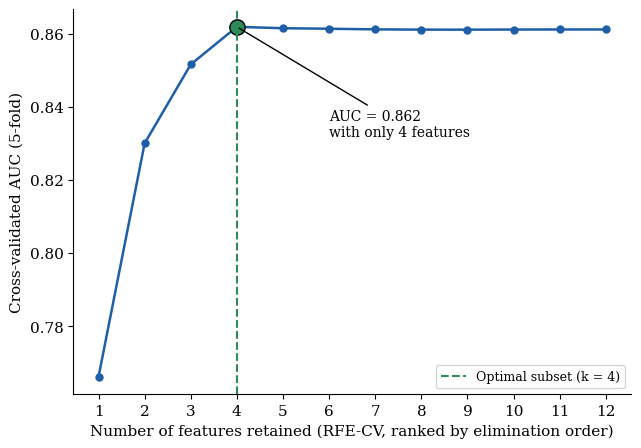

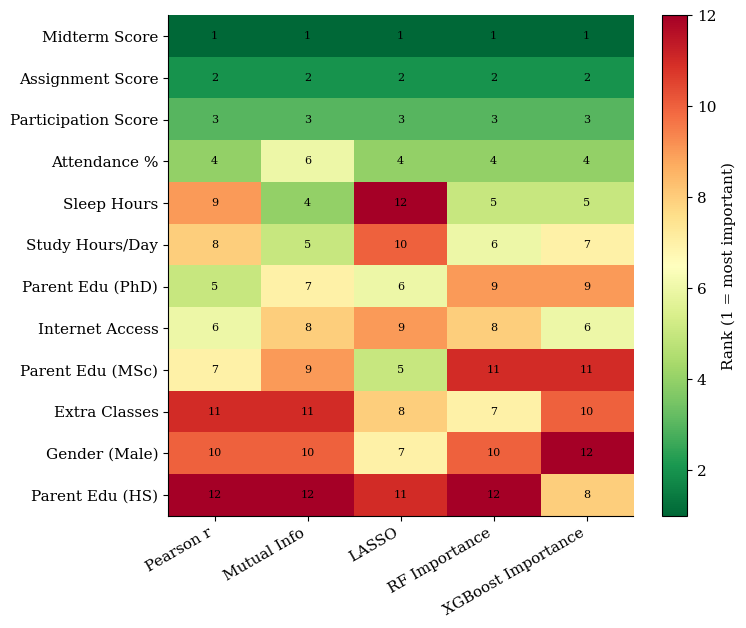

In [7]:
spw = (1 - y.mean()) / y.mean()
Xs = pd.DataFrame(StandardScaler().fit_transform(X), columns=CANDIDATES)

scores = pd.DataFrame(index=CANDIDATES)
scores["Pearson |r|"] = [abs(np.corrcoef(X[c], y)[0, 1]) for c in CANDIDATES]
scores["Mutual information"] = mutual_info_classif(X, y, discrete_features=[c not in NUMERIC for c in CANDIDATES],
                                                   random_state=SEED)
lasso = LogisticRegression(penalty="l1", C=LASSO_C, solver="liblinear", class_weight="balanced",
                           random_state=SEED).fit(Xs, y)
scores["LASSO |coef|"] = np.abs(lasso.coef_[0])
scores["RF importance"] = RandomForestClassifier(**RF_PARAMS, class_weight="balanced", random_state=SEED,
                                                 n_jobs=-1).fit(X, y).feature_importances_
scores["XGBoost importance"] = XGBClassifier(**XGB_PARAMS, scale_pos_weight=spw, eval_metric="logloss",
                                             random_state=SEED, n_jobs=-1).fit(X, y).feature_importances_
ranks = scores.rank(ascending=False, method="first").astype(int)

# RFE-CV
lr_est = LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)
rfecv = RFECV(lr_est, step=1, cv=StratifiedKFold(CV_RFE, shuffle=True, random_state=SEED),
              scoring="roc_auc", min_features_to_select=1, n_jobs=-1).fit(Xs, y)
trace = pd.DataFrame({"n_features": np.arange(1, len(CANDIDATES) + 1),
                      "mean_auc": rfecv.cv_results_["mean_test_score"],
                      "sd_auc": rfecv.cv_results_["std_test_score"]})
order = pd.Series(RFE(lr_est, n_features_to_select=1).fit(Xs, y).ranking_, index=CANDIDATES).sort_values()
k_opt = int(trace.loc[trace.mean_auc >= trace.mean_auc.max() - PARSIMONY_TOL, "n_features"].min())
SELECTED = list(order.index[:k_opt])

consensus = set.intersection(*[set(ranks.index[ranks[c] <= k_opt]) for c in ranks.columns])
converged = consensus == set(SELECTED)
print(f"RFE-CV optimum k = {k_opt} (plain arg-max k = {int(trace.loc[trace.mean_auc.idxmax(), 'n_features'])})")
print("Selected subset:", [LABELS[f] for f in SELECTED])
print("All techniques converge on this subset:", converged)
print("AUC trace:", dict(zip(trace.n_features, trace.mean_auc.round(3))))

t2 = pd.DataFrame(index=CANDIDATES)
for c in scores.columns:
    t2[c] = [f"{scores.loc[f, c]:.3f} ({ranks.loc[f, c]})" for f in CANDIDATES]
t2["RFE-CV"] = ["Selected" if f in SELECTED else "Not selected" for f in CANDIDATES]
t2 = t2.loc[ranks.mean(axis=1).sort_values().index]
t2.index = [LABELS[f] for f in t2.index]
print("\nTable 2: Feature rankings across six techniques"); save_table(t2.rename_axis("Feature").reset_index(), "Table2_feature_rankings")
trace.round(4).to_csv(f"{TAB}/RFECV_trace.csv", index=False)

# Figure 1: RFE-CV trace
fig, ax = plt.subplots(figsize=(7.2, 5))
ax.plot(trace.n_features, trace.mean_auc, "o-", color="#1f5fa8", lw=1.8, ms=5)
best = trace.mean_auc[k_opt - 1]
ax.plot(k_opt, best, "o", ms=11, color="#2e8b57", mec="k")
ax.axvline(k_opt, ls="--", color="#2e8b57", label=f"Optimal subset (k = {k_opt})")
ax.annotate(f"AUC = {best:.3f}\nwith only {k_opt} features", xy=(k_opt, best), xytext=(k_opt + 2, best - 0.03),
            arrowprops=dict(arrowstyle="-"), fontsize=10)
ax.set_xticks(trace.n_features); ax.legend(loc="lower right", fontsize=9)
ax.set_xlabel("Number of features retained (RFE-CV, ranked by elimination order)")
ax.set_ylabel(f"Cross-validated AUC ({CV_RFE}-fold)")
save_fig(fig, "Figure1_RFECV_trace")

# Figure 2: rank heat map
r = ranks.loc[ranks.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(r.values, cmap="RdYlGn_r", aspect="auto", vmin=1, vmax=len(r))
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        ax.text(j, i, r.values[i, j], ha="center", va="center", fontsize=8)
ax.set_yticks(range(len(r)), [LABELS[f] for f in r.index])
ax.set_xticks(range(r.shape[1]), ["Pearson r", "Mutual Info", "LASSO", "RF Importance", "XGBoost Importance"],
              rotation=30, ha="right")
fig.colorbar(im, ax=ax).set_label("Rank (1 = most important)")
save_fig(fig, "Figure2_rank_heatmap")


  training Logistic regression ...
  training Random forest ...
  training XGBoost ...
  training LightGBM ...
  training CatBoost ...
  training Stacked ensemble ...

Table 3: At-risk classification (12 features, 10-fold CV, mean ± SD)


,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic regression,0.765 ± 0.010,0.460 ± 0.014,0.777 ± 0.036,0.578 ± 0.019,0.862 ± 0.010
1,Random forest,0.771 ± 0.005,0.467 ± 0.008,0.748 ± 0.034,0.575 ± 0.014,0.855 ± 0.009
2,XGBoost,0.760 ± 0.008,0.453 ± 0.011,0.765 ± 0.022,0.569 ± 0.012,0.852 ± 0.006
3,LightGBM,0.770 ± 0.005,0.464 ± 0.007,0.723 ± 0.031,0.565 ± 0.013,0.848 ± 0.007
4,CatBoost,0.759 ± 0.005,0.453 ± 0.007,0.791 ± 0.028,0.576 ± 0.011,0.857 ± 0.008
5,Stacked ensemble,0.753 ± 0.009,0.446 ± 0.011,0.814 ± 0.035,0.576 ± 0.015,0.857 ± 0.009


Best model by mean AUC: Logistic regression
SMOTE vs class weighting


,Imbalance handling,AUC,F1
0,Class weighting,0.862 ± 0.010,0.578 ± 0.019
1,SMOTE (training folds only),0.862 ± 0.010,0.579 ± 0.019


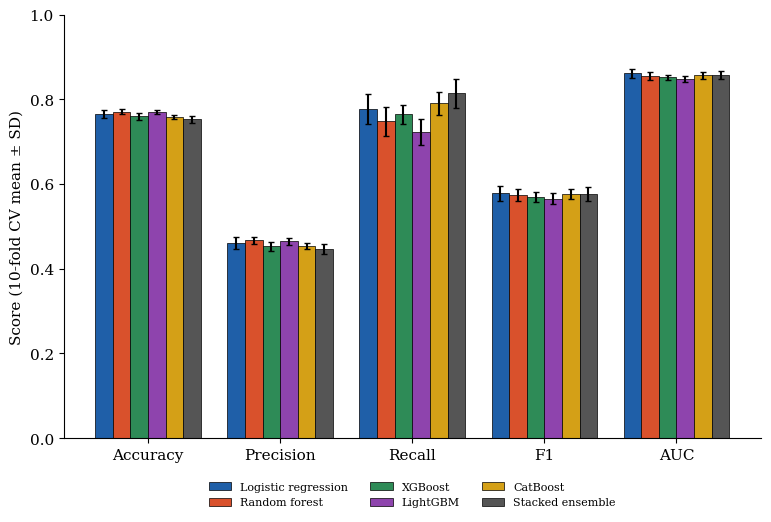

In [8]:
def cv10():
    return StratifiedKFold(CV_CLS, shuffle=True, random_state=SEED)

def logreg():
    return make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000,
                                                              random_state=SEED))

def make_models():
    trees = {
        "Random forest": RandomForestClassifier(**RF_PARAMS, class_weight="balanced", random_state=SEED, n_jobs=-1),
        "XGBoost": XGBClassifier(**XGB_PARAMS, scale_pos_weight=spw, eval_metric="logloss", random_state=SEED, n_jobs=-1),
        "LightGBM": LGBMClassifier(**LGBM_PARAMS, class_weight="balanced", random_state=SEED, n_jobs=-1, verbose=-1),
        "CatBoost": CatBoostClassifier(**CATBOOST_PARAMS, auto_class_weights="Balanced", random_seed=SEED, verbose=0),
    }
    models = {"Logistic regression": logreg(), **trees}
    models["Stacked ensemble"] = StackingClassifier(
        estimators=[(k.replace(" ", "_").lower(), v) for k, v in trees.items()],
        final_estimator=LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
        cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
    return models

def fold_metrics(model, Xm, ym):
    # Fold-wise metrics and out-of-fold probabilities.
    Xm = np.asarray(Xm); rows, oof = [], np.zeros(len(ym))
    for tr, te in cv10().split(Xm, ym):
        p = clone(model).fit(Xm[tr], ym[tr]).predict_proba(Xm[te])[:, 1]
        oof[te] = p; yh = (p >= THRESHOLD).astype(int)
        rows.append(dict(Accuracy=accuracy_score(ym[te], yh), Precision=precision_score(ym[te], yh, zero_division=0),
                         Recall=recall_score(ym[te], yh), F1=f1_score(ym[te], yh), AUC=roc_auc_score(ym[te], p)))
    return pd.DataFrame(rows), oof

F3 = CANDIDATES if TABLE3_FEATURE_SET == "all" else SELECTED
FOLDS, OOFS = {}, {}
for name, model in make_models().items():
    print("  training", name, "...")
    FOLDS[name], OOFS[name] = fold_metrics(model, X[F3], y)
t3 = pd.DataFrame({n: {m: fmt(d[m]) for m in d.columns} for n, d in FOLDS.items()}).T.rename_axis("Model").reset_index()
print(f"\nTable 3: At-risk classification ({len(F3)} features, 10-fold CV, mean ± SD)"); save_table(t3, "Table3_classification")
BEST = max(FOLDS, key=lambda k: FOLDS[k].AUC.mean())
print("Best model by mean AUC:", BEST)

# SMOTE vs class weighting (logistic regression)
smote = ImbPipeline([("scale", StandardScaler()), ("smote", SMOTE(random_state=SEED)),
                     ("lr", LogisticRegression(max_iter=2000, random_state=SEED))])
rows = []
for name, m in {"Class weighting": logreg(), "SMOTE (training folds only)": smote}.items():
    d, _ = fold_metrics(m, X[F3], y); rows.append({"Imbalance handling": name, "AUC": fmt(d.AUC), "F1": fmt(d.F1)})
print("SMOTE vs class weighting"); save_table(pd.DataFrame(rows), "SMOTE_vs_weighting")

# Figure 3
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC"]; names = list(FOLDS); w = 0.8 / len(names)
fig, ax = plt.subplots(figsize=(9, 5.5)); xs = np.arange(len(metrics))
for i, n in enumerate(names):
    ax.bar(xs + (i - (len(names) - 1) / 2) * w, [FOLDS[n][m].mean() for m in metrics], w,
           yerr=[FOLDS[n][m].std(ddof=1) for m in metrics], capsize=2, color=PALETTE[i], edgecolor="black", lw=0.5, label=n)
ax.set_xticks(xs, metrics); ax.set_ylim(0, 1); ax.set_ylabel("Score (10-fold CV mean ± SD)")
ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
save_fig(fig, "Figure3_classifier_comparison")


In [9]:
if RUN_NESTED:
    grids = {
        "Logistic regression": (logreg(), {"logisticregression__C": [0.01, 0.1, 1, 10]}),
        "XGBoost": (XGBClassifier(n_estimators=N_TREES, scale_pos_weight=spw, eval_metric="logloss",
                                  random_state=SEED, n_jobs=-1),
                    {"max_depth": [3, 5], "learning_rate": [0.05, 0.1]}),
        "LightGBM": (LGBMClassifier(n_estimators=N_TREES, class_weight="balanced", random_state=SEED,
                                    verbose=-1, n_jobs=-1),
                     {"num_leaves": [15, 31], "learning_rate": [0.05, 0.1]}),
        "Stacked ensemble": (make_models()["Stacked ensemble"], {"final_estimator__C": [0.1, 1, 10]}),
    }
    outer = StratifiedKFold(NESTED_OUTER, shuffle=True, random_state=SEED)
    inner = StratifiedKFold(NESTED_INNER, shuffle=True, random_state=SEED)
    rows = []
    for name, (est, grid) in grids.items():
        print("  tuning", name, "...")
        s = cross_val_score(GridSearchCV(est, grid, cv=inner, scoring="roc_auc"), X[F3], y, cv=outer, scoring="roc_auc")
        rows.append({"Model": name, "Tuned AUC (nested CV)": fmt(s)})
    print("Nested-CV tuned AUC"); save_table(pd.DataFrame(rows), "Nested_tuning")
else:
    print("Nested tuning skipped (RUN_NESTED = False).")


  tuning Logistic regression ...
  tuning XGBoost ...
  tuning LightGBM ...
  tuning Stacked ensemble ...
Nested-CV tuned AUC


,Model,Tuned AUC (nested CV)
0,Logistic regression,0.861 ± 0.006
1,XGBoost,0.857 ± 0.005
2,LightGBM,0.853 ± 0.006
3,Stacked ensemble,0.856 ± 0.006


Table 4: Calibration (Logistic regression, test split n = 2,000)


,Measure,Before calibration,After Platt scaling
0,Brier score,0.154,0.116
1,AUC,0.869,0.869


Risk tiers (observed at-risk rate, %)


,Risk tier,Calibrated probability,Observed at-risk rate,n
0,Low,0.00-0.33,10.2,1526
1,Medium,0.33-0.66,48.6,329
2,High,0.66-1.00,68.3,145


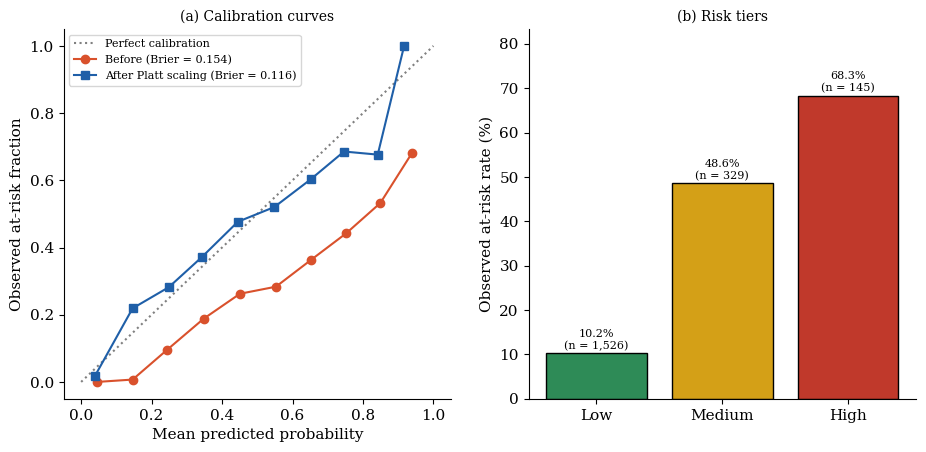

In [10]:
Xtr, Xte, ytr, yte = train_test_split(X[SELECTED], y, test_size=TEST_SIZE, stratify=y, random_state=SEED)
base_model = make_models()[BEST]
p_raw = clone(base_model).fit(Xtr, ytr).predict_proba(Xte)[:, 1]
p_cal = CalibratedClassifierCV(clone(base_model), method="sigmoid",
                               cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

t4a = pd.DataFrame([
    {"Measure": "Brier score", "Before calibration": round(brier_score_loss(yte, p_raw), 3),
     "After Platt scaling": round(brier_score_loss(yte, p_cal), 3)},
    {"Measure": "AUC", "Before calibration": round(roc_auc_score(yte, p_raw), 3),
     "After Platt scaling": round(roc_auc_score(yte, p_cal), 3)}])
rows = []
for lo, hi, name in RISK_TIERS:
    m = (p_cal >= lo) & (p_cal < hi)
    rows.append({"Risk tier": name, "Calibrated probability": f"{lo:.2f}-{min(hi, 1):.2f}",
                 "Observed at-risk rate": round(100 * yte[m].mean(), 1) if m.any() else np.nan, "n": int(m.sum())})
t4b = pd.DataFrame(rows)
print(f"Table 4: Calibration ({BEST}, test split n = {len(yte):,})"); save_table(t4a, "Table4_calibration")
print("Risk tiers (observed at-risk rate, %)"); save_table(t4b, "Table4_risk_tiers")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.8))
a.plot([0, 1], [0, 1], ":", color="grey", label="Perfect calibration")
for p, lab, col, mk in [(p_raw, "Before", "#d9512c", "o"), (p_cal, "After Platt scaling", "#1f5fa8", "s")]:
    fx, mx = calibration_curve(yte, p, n_bins=10)
    a.plot(mx, fx, marker=mk, color=col, label=f"{lab} (Brier = {brier_score_loss(yte, p):.3f})")
a.set_xlabel("Mean predicted probability"); a.set_ylabel("Observed at-risk fraction")
a.set_title("(a) Calibration curves", fontsize=10); a.legend(fontsize=8)
rates = t4b["Observed at-risk rate"].fillna(0)
bars = b.bar(t4b["Risk tier"], rates, color=["#2e8b57", "#d4a017", "#c0392b"], edgecolor="black")
for bar, rr, n in zip(bars, rates, t4b.n):
    b.text(bar.get_x() + bar.get_width() / 2, rr + 1, f"{rr:.1f}%\n(n = {n:,})", ha="center", fontsize=8)
b.set_ylabel("Observed at-risk rate (%)"); b.set_ylim(0, rates.max() + 15); b.set_title("(b) Risk tiers", fontsize=10)
save_fig(fig, "Figure4_calibration_tiers")


Table 5: Ablation study


,Feature set,AUC (mean ± SD),Change from full model
0,Full model (12 features),0.862 ± 0.010,-
1,Selected 4-feature subset only,0.862 ± 0.010,<0.001
2,Without assessment,0.637 ± 0.019,-0.225
3,Without engagement,0.830 ± 0.014,-0.032
4,Without behavioural,0.862 ± 0.010,<0.001
5,Without demographic,0.862 ± 0.010,<0.001
6,Assessment features only,0.830 ± 0.014,-
7,Engagement features only,0.639 ± 0.019,-
8,Behavioural features only,0.499 ± 0.018,-
9,Demographic features only,0.502 ± 0.021,-


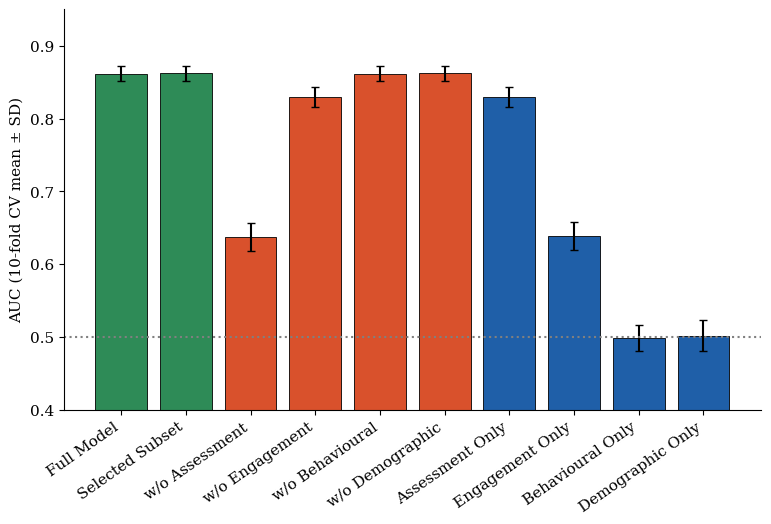

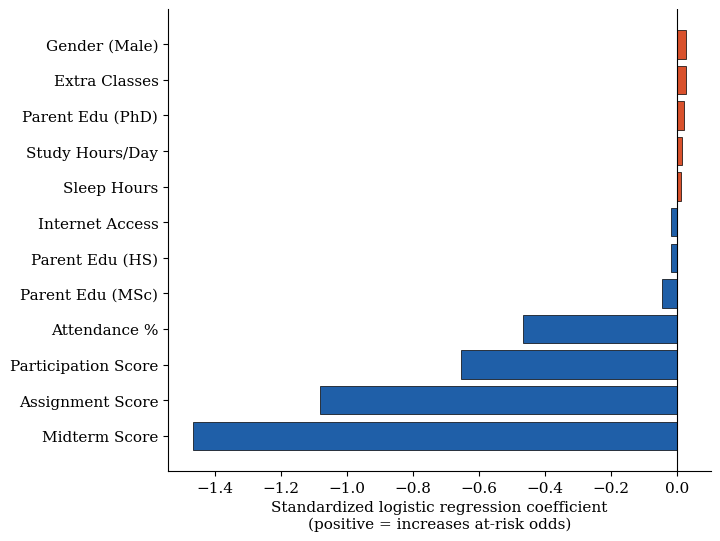

midterm                  -1.466
assignment               -1.081
participation            -0.655
attendance               -0.467
parent_edu_masters       -0.046
parent_edu_high_school   -0.017
internet_yes             -0.017
sleep_hours               0.011
study_hours               0.014
parent_edu_phd            0.021
extra_classes_yes         0.026
gender_male               0.027


In [11]:
configs = {"Full model (12 features)": CANDIDATES, f"Selected {len(SELECTED)}-feature subset only": SELECTED}
for g, feats in GROUPS.items():
    configs[f"Without {g.lower()}"] = [f for f in CANDIDATES if f not in feats]
for g, feats in GROUPS.items():
    configs[f"{g} features only"] = feats

AB = {}
for label, feats in configs.items():
    AB[label] = fold_metrics(logreg(), X[feats], y)[0].AUC
full = AB["Full model (12 features)"].mean(); rows = []
for label, a in AB.items():
    ch = a.mean() - full
    rows.append({"Feature set": label, "AUC (mean ± SD)": fmt(a),
                 "Change from full model": "-" if label.startswith("Full") or label.endswith("features only")
                 else ("<0.001" if abs(ch) < 0.001 else f"{ch:+.3f}")})
print("Table 5: Ablation study"); save_table(pd.DataFrame(rows), "Table5_ablation")

short = ["Full Model", "Selected Subset"] + [f"w/o {g}" for g in GROUPS] + [f"{g} Only" for g in GROUPS]
colors = ["#2e8b57"] * 2 + ["#d9512c"] * 4 + ["#1f5fa8"] * 4
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.bar(range(len(AB)), [a.mean() for a in AB.values()], yerr=[a.std(ddof=1) for a in AB.values()],
       capsize=3, color=colors, edgecolor="black", lw=0.6)
ax.axhline(0.5, ls=":", color="grey"); ax.set_ylim(0.4, 0.95)
ax.set_xticks(range(len(AB)), short, rotation=35, ha="right"); ax.set_ylabel("AUC (10-fold CV mean ± SD)")
save_fig(fig, "Figure5_ablation")

coef = pd.Series(logreg().fit(X, y)[-1].coef_[0], index=CANDIDATES).sort_values()
coef.round(3).rename("coefficient").rename_axis("feature").reset_index().to_csv(f"{TAB}/Figure6_coefficients.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh([LABELS[f] for f in coef.index], coef.values, color=["#d9512c" if v > 0 else "#1f5fa8" for v in coef.values],
        edgecolor="black", lw=0.5)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Standardized logistic regression coefficient\n(positive = increases at-risk odds)")
save_fig(fig, "Figure6_coefficients")
print(coef.round(3).to_string())


Table 6: Trained classifier vs zero-parameter baseline


,Model,AUC (mean ± SD),Fitted parameters
0,Fixed weighted combination (grading-rubric wei...,0.862 ± 0.010,0
1,Logistic regression (4 features),0.862 ± 0.010,5 (4 coefficients + intercept)


Paired t-test: t(9) = -0.81, p = 0.440
Statistical tests


,Comparison,Test,Statistic,p
0,Rubric baseline vs logistic regression,Paired t-test (fold-wise AUC),t(9) = -0.81,0.440
1,Logistic regression vs stacked ensemble,Paired t-test (fold-wise AUC),t(9) = 3.64,0.005
2,Logistic regression vs stacked ensemble,"McNemar (out-of-fold, 0.50)",chi2 = 28.14,<0.001


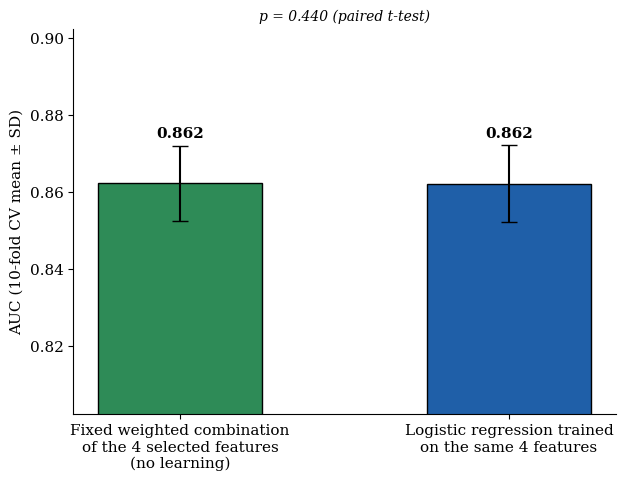

In [12]:
rubric = -sum(w * X[f] for f, w in RUBRIC_WEIGHTS.items()).to_numpy()   # higher score = lower risk
base_auc = np.array([roc_auc_score(y[te], rubric[te]) for _, te in cv10().split(X, y)])
lr_auc = fold_metrics(logreg(), X[SELECTED], y)[0].AUC.to_numpy()
t, p = stats.ttest_rel(lr_auc, base_auc)

t6 = pd.DataFrame([
    {"Model": "Fixed weighted combination (grading-rubric weights)", "AUC (mean ± SD)": fmt(base_auc), "Fitted parameters": "0"},
    {"Model": f"Logistic regression ({len(SELECTED)} features)", "AUC (mean ± SD)": fmt(lr_auc),
     "Fitted parameters": f"{len(SELECTED) + 1} ({len(SELECTED)} coefficients + intercept)"}])
print("Table 6: Trained classifier vs zero-parameter baseline"); save_table(t6, "Table6_baseline")
print(f"Paired t-test: t({len(lr_auc) - 1}) = {t:.2f}, p = {p:.3f}")

t2s, p2s = stats.ttest_rel(FOLDS["Logistic regression"].AUC, FOLDS["Stacked ensemble"].AUC)
ca = (OOFS["Logistic regression"] >= THRESHOLD).astype(int) == y
cb = (OOFS["Stacked ensemble"] >= THRESHOLD).astype(int) == y
mc = mcnemar([[np.sum(ca & cb), np.sum(ca & ~cb)], [np.sum(~ca & cb), np.sum(~ca & ~cb)]], exact=False, correction=True)
pf = lambda v: "<0.001" if v < 0.001 else f"{v:.3f}"
tests = pd.DataFrame([
    {"Comparison": "Rubric baseline vs logistic regression", "Test": "Paired t-test (fold-wise AUC)",
     "Statistic": f"t({len(lr_auc) - 1}) = {t:.2f}", "p": pf(p)},
    {"Comparison": "Logistic regression vs stacked ensemble", "Test": "Paired t-test (fold-wise AUC)",
     "Statistic": f"t({CV_CLS - 1}) = {t2s:.2f}", "p": pf(p2s)},
    {"Comparison": "Logistic regression vs stacked ensemble", "Test": "McNemar (out-of-fold, 0.50)",
     "Statistic": f"chi2 = {mc.statistic:.2f}", "p": pf(mc.pvalue)}])
print("Statistical tests"); save_table(tests, "Statistical_tests")

fig, ax = plt.subplots(figsize=(7, 5))
vals, sds = [base_auc.mean(), lr_auc.mean()], [base_auc.std(ddof=1), lr_auc.std(ddof=1)]
ax.bar([0, 1], vals, yerr=sds, capsize=6, color=["#2e8b57", "#1f5fa8"], edgecolor="black", width=0.5)
for i, v in enumerate(vals):
    ax.text(i, v + sds[i] + 0.002, f"{v:.3f}", ha="center", fontweight="bold")
k = len(SELECTED)
ax.set_xticks([0, 1], [f"Fixed weighted combination\nof the {k} selected features\n(no learning)",
                       f"Logistic regression trained\non the same {k} features"])
ax.set_ylim(max(0.5, min(vals) - 0.06), min(1, max(vals) + 0.04)); ax.set_ylabel("AUC (10-fold CV mean ± SD)")
ax.set_title(f"p = {p:.3f} (paired t-test)", fontsize=10, style="italic")
save_fig(fig, "Figure7_baseline_vs_trained")


  fitting Linear regression ...
  fitting Random forest ...
  fitting XGBoost ...
  fitting Stacked ensemble ...
Table 7a: Overall-score regression


,Model,R² (mean ± SD),MAE,RMSE
0,Linear regression,0.521 ± 0.015,6.14,7.08
1,Random forest,0.505 ± 0.016,6.21,7.19
2,XGBoost,0.501 ± 0.020,6.22,7.23
3,Stacked ensemble,0.521 ± 0.015,6.14,7.08


Table 7b: Ordinal grade model (test split)


,Measure,Value
0,Exact grade accuracy,58.90% (baseline: 50.75%)
1,Accuracy within one grade,100.00% (baseline: 97.9%)
2,Spearman rho,0.553 (p < 0.001)
3,Baseline = always predict,C


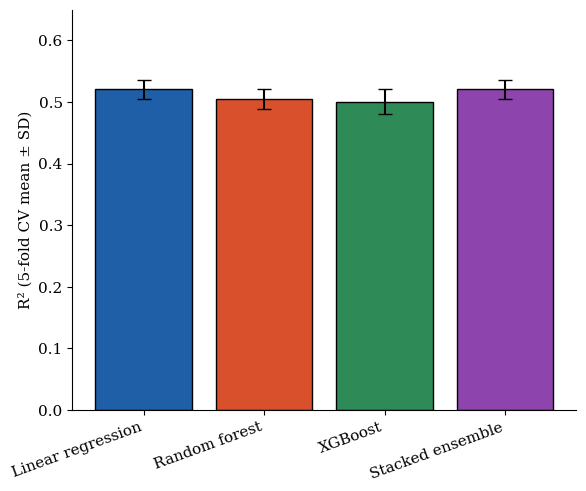

In [13]:
Xsel = X[SELECTED].to_numpy()
rf_r = RandomForestRegressor(n_estimators=N_TREES, max_depth=8, random_state=SEED, n_jobs=-1)
xg_r = XGBRegressor(n_estimators=N_TREES, max_depth=5, learning_rate=0.05, random_state=SEED, n_jobs=-1)
reg_models = {"Linear regression": LinearRegression(), "Random forest": rf_r, "XGBoost": xg_r,
              "Stacked ensemble": StackingRegressor([("lin", LinearRegression()), ("rf", rf_r), ("xgb", xg_r)],
                                                    final_estimator=RidgeCV(), cv=KFold(5, shuffle=True, random_state=SEED))}
R2, rows = {}, []
for name, m in reg_models.items():
    print("  fitting", name, "...")
    r2, mae, rmse = [], [], []
    for tr, te in KFold(CV_REG, shuffle=True, random_state=SEED).split(Xsel):
        pr = clone(m).fit(Xsel[tr], y_score[tr]).predict(Xsel[te])
        r2.append(r2_score(y_score[te], pr)); mae.append(mean_absolute_error(y_score[te], pr))
        rmse.append(np.sqrt(mean_squared_error(y_score[te], pr)))
    R2[name] = np.array(r2)
    rows.append({"Model": name, "R² (mean ± SD)": fmt(r2), "MAE": round(np.mean(mae), 2), "RMSE": round(np.mean(rmse), 2)})
print("Table 7a: Overall-score regression"); save_table(pd.DataFrame(rows), "Table7_regression")

# Ordinal letter-grade model
Xtr, Xte, gtr, gte = train_test_split(X[SELECTED], y_grade, test_size=TEST_SIZE, stratify=y_grade, random_state=SEED)
mu, sd = Xtr.mean(), Xtr.std()
om = OrderedModel(gtr, (Xtr - mu) / sd, distr="logit").fit(method="bfgs", disp=False, maxiter=2000)
pred = np.asarray(om.predict((Xte - mu) / sd)).argmax(axis=1)
mode = pd.Series(gtr).mode()[0]; rho, prho = spearmanr(pred, gte)
t7b = pd.DataFrame([
    {"Measure": "Exact grade accuracy", "Value": f"{100*np.mean(pred == gte):.2f}% (baseline: {100*np.mean(gte == mode):.2f}%)"},
    {"Measure": "Accuracy within one grade",
     "Value": f"{100*np.mean(abs(pred - gte) <= 1):.2f}% (baseline: {100*np.mean(abs(gte - mode) <= 1):.1f}%)"},
    {"Measure": "Spearman rho", "Value": f"{rho:.3f} (p {'< 0.001' if prho < 0.001 else f'= {prho:.3f}'})"},
    {"Measure": "Baseline = always predict", "Value": GRADE_ORDER[mode]}])
print("Table 7b: Ordinal grade model (test split)"); save_table(t7b, "Table7_ordinal")

fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.bar(list(R2), [v.mean() for v in R2.values()], yerr=[v.std(ddof=1) for v in R2.values()], capsize=5,
       color=PALETTE[:4], edgecolor="black")
ax.set_ylabel("R² (5-fold CV mean ± SD)"); ax.set_ylim(0, max(0.65, max(v.mean() for v in R2.values()) + 0.1))
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
save_fig(fig, "Figure8_regression")


In [14]:
_, oof_sel = fold_metrics(logreg(), X[SELECTED], y)
yhat = (oof_sel >= THRESHOLD).astype(int)
rows, gaps = [], []
for label, col in {"Gender": "gender", "Internet access": "internet", "Extra classes": "extra_classes",
                   "Parental education": "parent_edu"}.items():
    sub = []
    for g, idx in df.groupby(col).groups.items():
        i = np.asarray(list(idx)); yt, yp = y[i], yhat[i]
        tp, fn = np.sum((yt == 1) & (yp == 1)), np.sum((yt == 1) & (yp == 0))
        fp, tn = np.sum((yt == 0) & (yp == 1)), np.sum((yt == 0) & (yp == 0))
        sub.append({"Variable": label, "Group": g, "n": len(i), "At risk (%)": round(100 * yt.mean(), 1),
                    "Recall": round(tp / (tp + fn), 3), "FPR": round(fp / (fp + tn), 3),
                    "Precision": round(tp / (tp + fp), 3) if tp + fp else np.nan})
    s = pd.DataFrame(sub)
    gaps.append({"Variable": label, "Recall gap": round(s.Recall.max() - s.Recall.min(), 3),
                 "FPR gap": round(s.FPR.max() - s.FPR.min(), 3)})
    rows += sub
t8 = pd.DataFrame(rows); t8.loc[t8.Variable.duplicated(), "Variable"] = ""
print("Table 8: Error rates by demographic group"); save_table(t8, "Table8_subgroups")
print("Largest within-variable gaps"); save_table(pd.DataFrame(gaps), "Table8_gaps")


Table 8: Error rates by demographic group


,Variable,Group,n,At risk (%),Recall,FPR,Precision
0,Gender,Female,4987,20.5,0.786,0.239,0.459
1,,Male,5013,20.8,0.774,0.239,0.460
2,Internet access,No,4939,21.3,0.789,0.234,0.477
3,,Yes,5061,20.1,0.771,0.244,0.443
4,Extra classes,No,4913,20.8,0.793,0.248,0.457
5,,Yes,5087,20.5,0.767,0.230,0.463
6,Parental education,Bachelor,2527,20.3,0.750,0.229,0.455
7,,High School,2528,20.7,0.788,0.244,0.457
8,,Master,2487,20.0,0.795,0.235,0.458
9,,PhD,2458,21.8,0.787,0.248,0.469


Largest within-variable gaps


,Variable,Recall gap,FPR gap
0,Gender,0.012,0.000
1,Internet access,0.018,0.010
2,Extra classes,0.026,0.018
3,Parental education,0.045,0.019


In [15]:
with pd.ExcelWriter(f"{TAB}/all_tables.xlsx") as xw:
    for name, t in TABLES.items():
        t.to_excel(xw, sheet_name=name[:31], index=False)
summary = {"sample": profile, "selected_features": SELECTED, "converged": bool(converged),
           "rfe_k": k_opt, "best_classifier": BEST, "FAST": FAST}
with open(f"{OUT}/summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
shutil.make_archive("feature_driven_dtl_results", "zip", OUT)
print("Saved:", sorted(os.listdir(TAB)), sorted(os.listdir(FIG)), sep="\n")
try:
    from google.colab import files
    files.download("feature_driven_dtl_results.zip")
except ImportError:
    print("Not running in Colab: results are in feature_driven_dtl_results.zip")


Saved:
['Figure6_coefficients.csv', 'Nested_tuning.csv', 'RFECV_trace.csv', 'SMOTE_vs_weighting.csv', 'Statistical_tests.csv', 'Table1_descriptives.csv', 'Table2_feature_rankings.csv', 'Table3_classification.csv', 'Table4_calibration.csv', 'Table4_risk_tiers.csv', 'Table5_ablation.csv', 'Table6_baseline.csv', 'Table7_ordinal.csv', 'Table7_regression.csv', 'Table8_gaps.csv', 'Table8_subgroups.csv', 'all_tables.xlsx']
['Figure1_RFECV_trace.jpg', 'Figure2_rank_heatmap.jpg', 'Figure3_classifier_comparison.jpg', 'Figure4_calibration_tiers.jpg', 'Figure5_ablation.jpg', 'Figure6_coefficients.jpg', 'Figure7_baseline_vs_trained.jpg', 'Figure8_regression.jpg']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>